<a href="https://colab.research.google.com/github/Pascingo/CTA-media-analysis/blob/main/Stage_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
!pip install -q -r https://raw.githubusercontent.com/Pascingo/CTA-media-analysis/main/requirements.txt

import os
import re
import json
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import gdown
from tqdm.auto import tqdm
import hashlib
from sentence_transformers import SentenceTransformer
from google.colab import drive
import textwrap
import time

# Same settings as in Stage 1
TEXT_COLUMN = "content"
START_DATE = "2024-09-01"
END_DATE = "2026-08-31"

GOVERNANCE_KEYWORDS = [
    "security", "accountability", "bias", "fairness",
    "regulatory", "regulation", "governance", "policy",
    "ethics", "compliance", "law"
]
MIN_KEYWORD_HITS = 5
RANDOM_STATE = 42

# Folders and files
DATA_FOLDER = "data"

# Stage 3 results are saved on Google Drive, so that caches survive a runtime reset

drive.mount("/content/drive")
STAGE3_FOLDER = "/content/drive/MyDrive/CTA-media-analysis/stage3"
os.makedirs(STAGE3_FOLDER, exist_ok=True)

DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/14cAxvtxuTfwENtSDCmGcRpl6qhl-z62z"

DATASET_FILE     = os.path.join(DATA_FOLDER, "ai_media_dataset_20260911.csv")
STAGE1_GOV_FILE  = os.path.join(DATA_FOLDER, "ai_governance_cleaned.csv")
ENTITIES_FILE    = os.path.join(DATA_FOLDER, "entities_spacy.csv")
LANGEXTRACT_FILE = os.path.join(DATA_FOLDER, "langextract_ollama_25pm.jsonl")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Download of the Stage 1 data (Pascal)

We download the files from our public Google Drive folder: the fixed dataset version (2026-09-11), the Stage 1 governance corpus, the spaCy entities and the LangExtract results. The download is skipped if the files are already in the folder `data`.

In [2]:
STAGE1_FILES = [DATASET_FILE, STAGE1_GOV_FILE, ENTITIES_FILE, LANGEXTRACT_FILE]

if not all(os.path.exists(f) for f in STAGE1_FILES):
    gdown.download_folder(DRIVE_FOLDER_URL, output=DATA_FOLDER, quiet=True)

for f in STAGE1_FILES:
    if not os.path.exists(f):
        raise FileNotFoundError(f"{f} not found. Please check the Google Drive folder.")
    print(f"{f:<45} {os.path.getsize(f) / 1e6:>8.1f} MB")

data/ai_media_dataset_20260911.csv               529.7 MB
data/ai_governance_cleaned.csv                   438.6 MB
data/entities_spacy.csv                          220.6 MB
data/langextract_ollama_25pm.jsonl                 2.7 MB


### Reconstructing the Stage 1 corpus with document IDs (Pascal)

In Stage 1 we saved the governance corpus without its index. The spaCy entities and the LangExtract results, however, refer to the articles by this index (`doc_id`). We therefore repeat the cleaning steps of Stage 1 on the original dataset. The steps are deterministic, so we get the same articles with the same `doc_id`.

Two checks make sure this worked:

1. The number of articles and the titles must be identical to `ai_governance_cleaned.csv`.
2. All `doc_id`s in the LangExtract results must exist in the reconstructed corpus.

We keep the **full cleaned corpus** (`df`), and not only the 12,393 Stage 1 articles. The new topic filter in Part 1 has to be evaluated on all articles, so that we also see relevant articles that the Stage 1 filter missed (recall). The column `in_stage1` marks the articles of the Stage 1 corpus.

In [3]:
# 1. Same cleaning as in Stage 1 (sections 2 and 3)
df = pd.read_csv(DATASET_FILE, usecols=["title", "date", "content", "domain", "url", "tags"])
df = df.dropna(subset=[TEXT_COLUMN])
df = df.drop_duplicates(subset=[TEXT_COLUMN])

df["published_at"] = pd.to_datetime(df["date"], errors="coerce")
df = df[(df["published_at"] >= START_DATE) & (df["published_at"] <= END_DATE)].copy()

df["cleaned_text"] = df[TEXT_COLUMN].apply(
    lambda t: unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode()
)
df["cleaned_text"] = (
    df["cleaned_text"]
    .str.lower()
    .str.replace(r"<[^>]+>", " ", regex=True)
    .str.replace(r"[-/]", " ", regex=True)
    .str.replace(r"[^a-z0-9\s.,!?]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

pattern = r"\b(?:" + "|".join(GOVERNANCE_KEYWORDS) + r")\b"
df["gov_keyword_hits"] = df["cleaned_text"].str.count(pattern)
df["in_stage1"] = df["gov_keyword_hits"] >= MIN_KEYWORD_HITS
df.index.name = "doc_id"

# 2. Check 1: same articles as the saved Stage 1 corpus
df_gov_s1 = pd.read_csv(STAGE1_GOV_FILE)
stage1_ids = df.index[df["in_stage1"]]

assert len(stage1_ids) == len(df_gov_s1), "Number of articles differs from Stage 1."
assert (
    df.loc[stage1_ids, "title"].fillna("").values == df_gov_s1["title"].fillna("").values
).all(), "Titles differ from Stage 1."

# Take over the columns computed in Stage 1 (spaCy lemmas, sentiment)
for col in ["processed_text", "sentiment_polarity"]:
    df.loc[stage1_ids, col] = df_gov_s1[col].values

# 3. Check 2: the LangExtract results refer to existing articles
lx_doc_ids = pd.read_json(LANGEXTRACT_FILE, lines=True)["doc_id"]
share_found = lx_doc_ids.isin(stage1_ids).mean()
assert share_found == 1.0, f"Only {share_found:.1%} of the LangExtract doc_ids were found."

print(f"Full cleaned corpus:        {len(df):>6,} articles")
print(f"Stage 1 governance corpus:  {df['in_stage1'].sum():>6,} articles")
print(f"LangExtract articles found: {lx_doc_ids.nunique():>6,} (100%)")

Full cleaned corpus:        47,444 articles
Stage 1 governance corpus:  12,393 articles
LangExtract articles found:    599 (100%)


# 1. Addressing the Stage 1 feedback

The feedback on Stage 1 named three problems:

1. Several topics of our corpus are about **broader politics, energy and enterprise technology** rather than AI Governance. Our topic filter was too broad.
2. The relation extraction produced many **inconsistent predicates** and **source-alignment problems**. After schema filtering, very few factual relations remained.
3. The co-occurrence graph is useful for exploration, but it is **not factual evidence**.

These problems directly affect the RAG system: irrelevant articles become irrelevant retrieved passages, and wrong relations become wrong "facts" in the answers. We therefore address them first.

## 1.1 Tightened topic filter (Pascal)

The Stage 1 filter counted eleven general keywords and kept every article with at least 5 hits. It had two weaknesses:

- **Generic words** such as *security*, *policy* and *law* also appear in articles about cybersecurity products, US domestic politics or company policies.
- **Absolute counts** favour long articles: a 4,000-word article about energy markets reaches 5 hits easily, even if governance is only a side remark.

The new filter works in three steps:

1. **Governance score:** We count specific governance terms in two groups. *Strong terms* (e.g. *AI Act*, *code of practice*, *AI safety institute*, *copyright*, *lawsuit*) are clearly about governance on their own and get weight 3. *Medium terms* (e.g. *regulation*, *accountability*, *bias*, *oversight*) get weight 1. The generic words *security*, *policy* and *law* are no longer counted. We divide the weighted hits by the article length (**hits per 1,000 words**), so that long articles are not favoured.
2. **Off-topic score:** For the three confounders named in the feedback (politics, energy, enterprise technology), we count typical terms in the same way. The term lists are based on our Stage 1 topics 2, 3, 4, 5 and 7.
3. **Decision rule:** An article is kept if governance is dense enough, appears in the title or across several distinct terms, and is **at least as dense as the strongest off-topic vocabulary**. In other words, governance has to be the main subject, not a side remark.

The thresholds in this section are **provisional**. In section 1.2 we evaluate the filter on a manually annotated sample and choose the final thresholds there.

In [4]:
import hashlib

# Strong terms: clearly about AI Governance on their own (weight 3)
STRONG_TERMS = [
    r"ai act", r"code of practice", r"ai (?:safety|security) institutes?",
    r"executive orders?", r"gdpr", r"digital services act", r"responsible ai",
    r"ai governance", r"ai regulations?", r"ai safety", r"ai ethics",
    r"algorithmic bias", r"sb 53", r"sb 1047", r"frontier ai", r"deepfakes?",
    r"copyright", r"lawsuits?", r"data protection", r"ai liability",
    # AI security is part of our track
    r"ai security", r"prompt injections?", r"adversarial attacks?", r"(?:data|model) poisoning",
]

# Medium terms: typical governance vocabulary (weight 1)
MEDIUM_TERMS = [
    r"regulations?", r"regulatory", r"regulators?", r"legislation", r"lawmakers?",
    r"governance", r"accountability", r"fairness", r"bias(?:es|ed)?", r"discrimination",
    r"ethic(?:s|al)", r"transparency", r"oversight", r"liability", r"compliance",
    r"privacy", r"audits?", r"watermark(?:s|ing)?", r"red teaming", r"jailbreaks?",
    r"misinformation", r"ai risks?",
]

# Off-topic vocabulary for the three confounders named in the feedback
OFFTOPIC_TERMS = {
    "politics": [
        r"elections?", r"campaigns?", r"voters?", r"democrats?", r"republicans?",
        r"tariffs?", r"trade war", r"immigration", r"ukraine", r"russia",
        r"israel", r"gaza", r"iran", r"nato", r"military",
    ],
    "energy": [
        r"energy", r"electricity", r"power grids?", r"grid", r"nuclear",
        r"gigawatts?", r"megawatts?", r"utilities", r"oil", r"gas", r"solar",
        r"emissions", r"data centers?",
    ],
    "enterprise": [
        r"revenue", r"earnings", r"quarterly", r"shares", r"stock", r"investors?",
        r"valuation", r"funding round", r"ipo", r"customers?", r"enterprises?",
        r"saas", r"hybrid cloud", r"red hat", r"kubernetes", r"apis?",
        r"developers?", r"workflows?", r"productivity", r"mcp",
    ],
}


def count_terms(texts, terms, desc):
    """Count every term in every text in ONE pass per text.
    Each term is its own capture group; match.lastindex tells us which term matched."""
    regex = re.compile("|".join(rf"(\b{t}\b)" for t in terms))
    counts = np.zeros((len(texts), len(terms)), dtype=np.int32)
    for i, text in enumerate(tqdm(texts, desc=desc)):
        for match in regex.finditer(text):
            counts[i, match.lastindex - 1] += 1
    return pd.DataFrame(counts, columns=terms, index=texts.index)


# Cache: the file name contains a hash of the term lists,
# so the features are recomputed automatically when a list changes
term_hash = hashlib.md5(
    json.dumps([STRONG_TERMS, MEDIUM_TERMS, OFFTOPIC_TERMS]).encode()
).hexdigest()[:8]
TOPIC_FEATURES_FILE = os.path.join(STAGE3_FOLDER, f"topic_features_{term_hash}.parquet")

df["cleaned_title"] = (
    df["title"].fillna("").astype(str).str.lower()
    .str.replace(r"[-/]", " ", regex=True)
    .str.replace(r"[^a-z0-9\s.,!?]", "", regex=True)
)
df["n_words"] = df["cleaned_text"].str.count(" ") + 1

if os.path.exists(TOPIC_FEATURES_FILE):
    features = pd.read_parquet(TOPIC_FEATURES_FILE)
    print("Loaded topic features from cache.")
else:
    strong_counts = count_terms(df["cleaned_text"], STRONG_TERMS, "strong terms")
    medium_counts = count_terms(df["cleaned_text"], MEDIUM_TERMS, "medium terms")

    features = pd.DataFrame(index=df.index)
    features["gov_strong_hits"] = strong_counts.sum(axis=1)
    features["gov_medium_hits"] = medium_counts.sum(axis=1)
    features["gov_distinct_terms"] = (strong_counts > 0).sum(axis=1) + (medium_counts > 0).sum(axis=1)

    title_pattern = "|".join(rf"\b{t}\b" for t in STRONG_TERMS + MEDIUM_TERMS)
    features["gov_in_title"] = df["cleaned_title"].str.contains(title_pattern, regex=True)

    for category, terms in OFFTOPIC_TERMS.items():
        features[f"off_{category}_hits"] = count_terms(df["cleaned_text"], terms, category).sum(axis=1)

    features.to_parquet(TOPIC_FEATURES_FILE)

df = df.drop(columns=features.columns, errors="ignore").join(features)

# Densities per 1,000 words
df["gov_score_per_1k"] = 1000 * (3 * df["gov_strong_hits"] + df["gov_medium_hits"]) / df["n_words"]
for category in OFFTOPIC_TERMS:
    df[f"off_{category}_per_1k"] = 1000 * df[f"off_{category}_hits"] / df["n_words"]

OFF_COLUMNS = [f"off_{c}_per_1k" for c in OFFTOPIC_TERMS]
df["off_max_per_1k"] = df[OFF_COLUMNS].max(axis=1)
df["off_main_category"] = df[OFF_COLUMNS].idxmax(axis=1).str.replace("off_", "").str.replace("_per_1k", "")

df[["n_words", "gov_score_per_1k", "gov_distinct_terms"] + OFF_COLUMNS].describe().round(2)

Loaded topic features from cache.


,n_words,gov_score_per_1k,gov_distinct_terms,off_politics_per_1k,off_energy_per_1k,off_enterprise_per_1k
count,47444.00,47444.00,47444.00,47444.00,47444.00,47444.00
mean,1659.03,3.61,1.92,0.83,1.47,5.95
std,1154.28,7.45,2.50,2.84,5.01,8.03
min,210.00,0.00,0.00,0.00,0.00,0.00
25%,969.00,0.00,0.00,0.00,0.00,0.67
50%,1248.00,1.15,1.00,0.00,0.00,2.98
75%,1853.00,3.80,3.00,0.00,0.84,8.15
max,9533.00,129.73,28.00,61.77,96.92,80.00


### Lexical candidate filter (Pascal)

A first run showed that the lexical score alone is not precise enough. Articles about healthcare, construction, solar panels or tax reached a governance score of 5–9 only through general words such as *privacy*, *compliance* or *transparency*. Such topics cannot all be covered by off-topic lists. The lexical step is therefore used as a **high-recall candidate filter**: it should keep almost all real governance articles, and precision is added in the next step with a semantic score.

An article becomes a candidate (`gov_lexical`) if all three conditions are met:

1. `gov_score_per_1k >= MIN_GOV_SCORE`;
2. the title contains a governance term, **or** the text contains at least `MIN_DISTINCT_TERMS` different governance terms;
3. `gov_score_per_1k >= off_max_per_1k`: governance is at least as dense as the strongest off-topic vocabulary.

We also added four AI-security terms (e.g. *prompt injection*, *data poisoning*). The first run had removed an article about securing agentic AI systems, although AI security is part of our track.

In [5]:
# Loose thresholds: the candidate filter should favour recall
MIN_GOV_SCORE = 3
MIN_DISTINCT_TERMS = 3


def apply_lexical_filter(data, min_score, min_distinct):
    return (
        (data["gov_score_per_1k"] >= min_score)
        & (data["gov_in_title"] | (data["gov_distinct_terms"] >= min_distinct))
        & (data["gov_score_per_1k"] >= data["off_max_per_1k"])
    )


for min_score in [2, 3, 5, 8]:
    n = apply_lexical_filter(df, min_score, MIN_DISTINCT_TERMS).sum()
    print(f"gov_score_per_1k >= {min_score}: {n:>6,} articles ({n / len(df):.1%})")

df["gov_lexical"] = apply_lexical_filter(df, MIN_GOV_SCORE, MIN_DISTINCT_TERMS)

print()
display(pd.crosstab(df["in_stage1"], df["gov_lexical"], margins=True))

gov_score_per_1k >= 2:  7,667 articles (16.2%)
gov_score_per_1k >= 3:  7,264 articles (15.3%)
gov_score_per_1k >= 5:  6,105 articles (12.9%)
gov_score_per_1k >= 8:  4,464 articles (9.4%)



gov_lexical,False,True,All
in_stage1,,,
False,32747,2304,35051
True,7433,4960,12393
All,40180,7264,47444


### First check: which articles change? (Pascal)

We compare three groups: the articles that **both** filters keep, the articles that **only Stage 1** kept (removed by the new filter), and the articles that **only the new filter** keeps (added). If the new filter works as intended, the removed articles should have a much higher off-topic density. A random sample of titles from each group gives a first qualitative impression.

In [6]:
# Remove the column of the first, discarded filter version
df = df.drop(columns=["gov_v2"], errors="ignore")

groups = {
    "kept by both":           df["in_stage1"] & df["gov_lexical"],
    "removed (only Stage 1)": df["in_stage1"] & ~df["gov_lexical"],
    "added (only lexical)":   ~df["in_stage1"] & df["gov_lexical"],
}

comparison = pd.DataFrame({
    name: df.loc[mask, ["gov_score_per_1k"] + OFF_COLUMNS].mean() for name, mask in groups.items()
}).T
comparison.insert(0, "articles", [mask.sum() for mask in groups.values()])
display(comparison.round(2))

print("Main off-topic category of the removed articles:")
display(df.loc[groups["removed (only Stage 1)"], "off_main_category"].value_counts())

for name, mask in groups.items():
    print(f"\n--- {name} ---")
    sample = df.loc[mask].sample(n=min(10, mask.sum()), random_state=RANDOM_STATE)
    for title, score, off in zip(sample["title"], sample["gov_score_per_1k"], sample["off_max_per_1k"]):
        print(f"gov={score:5.1f}  off={off:5.1f}  {str(title)[:110]}")

,articles,gov_score_per_1k,off_politics_per_1k,off_energy_per_1k,off_enterprise_per_1k
kept by both,4960,16.80,0.51,0.51,3.68
removed (only Stage 1),7433,3.62,1.86,1.90,8.42
added (only lexical),2304,9.29,0.56,0.49,2.24


Main off-topic category of the removed articles:


,count
off_main_category,
enterprise,4940
politics,1642
energy,851



--- kept by both ---
gov=  5.7  off=  3.5  Tesla Cybercab Prototypes Tested in Austin for Robotaxi Launch
gov= 19.3  off=  1.2  No ‘ woke AI’ in Washington, says Trump, as he launches AI action plan
gov=  7.4  off=  1.4  Laura Zommer
gov=  5.0  off=  0.8  The Revolutionizing Impact of IoT on Manufacturing Inspection: A Comprehensive Guide
gov= 17.0  off=  1.4  Privacy notice
gov= 20.4  off=  1.9  Enhancing India's Defense with Indigenous UAVs: A Tata Elxsi and Garuda Aerospace Initiative
gov= 50.1  off=  4.3  What is explainable AI?
gov=  8.6  off=  1.6  Getting Secure, Scalable Payment Processing Right for Global Users — Omvaris Limited's Take
gov=  8.7  off=  5.4  Supply chain metrics that matter in 2026
gov=  8.3  off=  3.7  On-Device Annotation: Labeling Data for Real-Time Models

--- removed (only Stage 1) ---
gov=  3.0  off= 15.7  What is MLOps?
gov=  0.4  off= 16.4  Military Land Vehicles Market Size, Share, and Regional Trends 2026-2033
gov=  1.5  off= 15.5  Foreword: An Elect

### Results of the lexical candidate filter (Pascal)

The candidate filter keeps **7,264 articles** (15.3% of the corpus). 4,960 of them were already in the Stage 1 corpus, and 2,304 are new. 7,433 Stage 1 articles are removed.

| Group | Articles | Governance score | Politics | Energy | Enterprise |
|---|---:|---:|---:|---:|---:|
| kept by both | 4,960 | 16.80 | 0.51 | 0.51 | 3.68 |
| removed (only Stage 1) | 7,433 | 3.62 | 1.86 | 1.90 | 8.42 |
| added (only lexical) | 2,304 | 9.29 | 0.56 | 0.49 | 2.24 |

*(densities per 1,000 words)*

**Removed articles:** Their governance density is almost five times lower than in the kept articles, and their off-topic density is three to four times higher. The main off-topic category of the removed articles is **enterprise technology (4,940)**, followed by **politics (1,642)** and **energy (851)**. These are exactly the three confounders named in the Stage 1 feedback. The sample titles confirm this: MLOps, API management, election forewords, military vehicle market reports.

**Added articles:** The new filter finds governance articles that Stage 1 missed, e.g. *"Copyright Office Publishes Report on Copyrightability of AI Works"* or *"EU Fines Google €2.95 Billion"*. These articles are often short, so they did not reach 5 absolute keyword hits, although governance is their main subject.

**Remaining problems:** The lexical score alone is not precise enough. Near the threshold (score 3–5) we still find unrelated articles (AI for SEO, meme culture, AI PCs). Some kept articles are not about governance at all: a Tesla robotaxi test, IoT in manufacturing, payment processing. Others are not news articles: a website *"Privacy notice"* and a person profile page. General words such as *privacy* or *compliance* appear in many industries, and we cannot write off-topic lists for every industry. We therefore add a semantic score in the next step.

### Semantic score (Pascal)

For every candidate article we compute a sentence embedding of the **title and the first 200 words**. The first paragraph of a news article usually states its main subject. We compare this embedding with two groups of short descriptions (**prototypes**):

- **Governance prototypes** describe the sub-themes of our track: regulation, enforcement, lawsuits, bias and fairness, AI safety and security, transparency and accountability, privacy, deepfakes.
- **Off-topic prototypes** describe the false positives we observed: politics, energy, enterprise software, earnings and funding, AI applications in industries, market reports, general cybersecurity products and website boilerplate.

The **semantic margin** is the highest similarity to a governance prototype minus the highest similarity to an off-topic prototype. A positive margin means that the article is closer to governance than to any off-topic theme.

We use `BAAI/bge-small-en-v1.5`, a small and fast embedding model. The embeddings are only computed for the 7,264 candidates and are cached on Google Drive.

In [7]:


EMBEDDING_MODEL = "BAAI/bge-small-en-v1.5"
LEAD_WORDS = 200

GOV_PROTOTYPES = {
    "regulation":     "Governments and lawmakers pass laws and regulations for artificial intelligence, such as the EU AI Act.",
    "enforcement":    "A regulator investigates an AI company, imposes a fine or orders it to change its practices.",
    "lawsuits":       "A lawsuit about copyright infringement or liability for AI-generated content.",
    "bias_fairness":  "Concerns about algorithmic bias, discrimination and fairness of AI systems.",
    "safety_security":"AI safety and security: testing frontier models, red teaming, prompt injection and misuse risks.",
    "accountability": "Debate about transparency, accountability and human oversight of AI systems.",
    "privacy":        "Data protection authorities examine how AI models use personal data and privacy.",
    "deepfakes":      "Rules and policies against deepfakes, AI-generated misinformation and harmful content.",
}

OFF_PROTOTYPES = {
    "politics":       "Election campaigns, political parties, wars and foreign policy.",
    "energy":         "Energy demand of data centers, electricity grids and power plants.",
    "earnings":       "A company reports revenue and earnings, or a startup raises a funding round.",
    "enterprise":     "An enterprise software vendor launches a new product for developers and IT teams.",
    "industry_use":   "How AI is used in healthcare, manufacturing, finance or supply chains to improve efficiency.",
    "market_report":  "A market research report with market size, growth forecast and key players.",
    "cybersecurity":  "A cybersecurity company offers threat detection and protection against hackers.",
    "boilerplate":    "Privacy notice, cookie policy, terms of use or a personal profile page on a website.",
}


def lead_text(title, content, n_words=LEAD_WORDS):
    content = re.sub(r"<[^>]+>", " ", str(content))
    return f"{title}. " + " ".join(content.split()[:n_words])


candidates = df[df["gov_lexical"]]
LEAD_EMB_FILE = os.path.join(STAGE3_FOLDER, "lead_embeddings.npz")

embedder = SentenceTransformer(EMBEDDING_MODEL)

# Load the cached embeddings only if they belong to exactly the same candidate articles
lead_emb = None
if os.path.exists(LEAD_EMB_FILE):
    cached = np.load(LEAD_EMB_FILE)
    if np.array_equal(cached["doc_ids"], candidates.index.to_numpy()):
        lead_emb = cached["embeddings"]
        print("Loaded lead embeddings from cache.")

if lead_emb is None:
    leads = [lead_text(t, c) for t, c in zip(candidates["title"].fillna(""), candidates["content"])]
    lead_emb = embedder.encode(leads, batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    np.savez(LEAD_EMB_FILE, doc_ids=candidates.index.to_numpy(), embeddings=lead_emb)

gov_proto_emb = embedder.encode(list(GOV_PROTOTYPES.values()), normalize_embeddings=True)
off_proto_emb = embedder.encode(list(OFF_PROTOTYPES.values()), normalize_embeddings=True)

# Cosine similarity (embeddings are normalized, so the dot product is enough)
gov_sim = lead_emb @ gov_proto_emb.T
off_sim = lead_emb @ off_proto_emb.T

df.loc[candidates.index, "sem_gov"] = gov_sim.max(axis=1)
df.loc[candidates.index, "sem_off"] = off_sim.max(axis=1)
df.loc[candidates.index, "sem_margin"] = gov_sim.max(axis=1) - off_sim.max(axis=1)
df.loc[candidates.index, "sem_gov_label"] = np.array(list(GOV_PROTOTYPES))[gov_sim.argmax(axis=1)]
df.loc[candidates.index, "sem_off_label"] = np.array(list(OFF_PROTOTYPES))[off_sim.argmax(axis=1)]

df.loc[candidates.index, ["sem_gov", "sem_off", "sem_margin"]].describe().round(3)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/114 [00:00<?, ?it/s]

,sem_gov,sem_off,sem_margin
count,7264.000,7264.000,7264.000
mean,0.628,0.621,0.007
std,0.066,0.055,0.063
min,0.362,0.435,-0.287
25%,0.586,0.583,-0.032
50%,0.633,0.621,0.008
75%,0.673,0.658,0.049
max,0.832,0.800,0.283


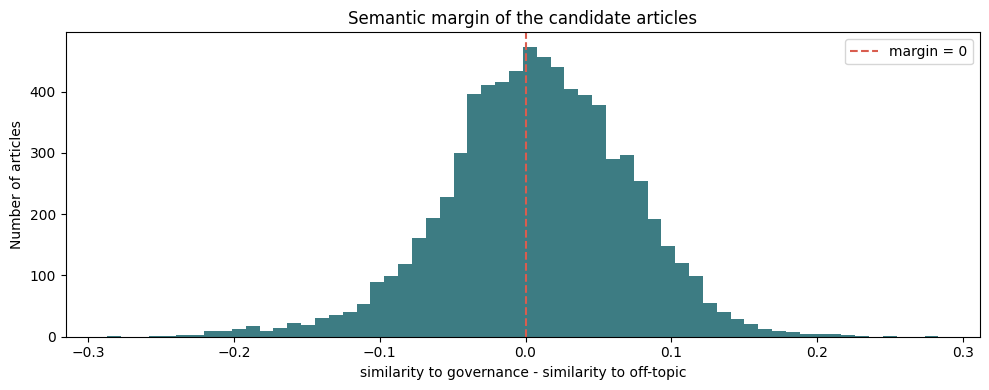


--- Q1 (lowest): margin -0.287 to -0.041 ---
-0.047  [industry_use   ] LumiQuant Academy Leads the Global Smart Trading Education Revolution with Quantyraxis AI, the 
-0.073  [market_report  ] OnlyFans in 2026: Is It Still Worth It for Gen Z Creators?
-0.195  [market_report  ] E-Learning Market Growth, Size, and Business Forecast 2026-2033
-0.046  [energy         ] New Smart Windows that are Self-Cleaning & Energy Efficient
-0.075  [industry_use   ] AI is Transforming Consumer Packaged Goods ( CPG): Are You Keeping Up?
-0.080  [market_report  ] Midyear update 2025 AI predictions: PwC
-0.062  [enterprise     ] Leona Health Raises $ 14M from a16z for WhatsApp AI Co-Pilot Aiding LatAm Doctors
-0.093  [market_report  ] KPMG Careers: Experienced Professionals

--- Q2: margin -0.040 to -0.007 ---
-0.033  [industry_use   ] Vendor Payment Automation
-0.026  [enterprise     ] Discussion with Professor Marina Jirotka, Human Centered Computing, University of Oxford
-0.011  [industry_use   ] Adva

gov_v2,False,True,All
in_stage1,,,
False,33759,1292,35051
True,9655,2738,12393
All,43414,4030,47444


In [8]:
cand = df[df["gov_lexical"]].copy()

# 1. Distribution of the semantic margin
plt.figure(figsize=(10, 4))
plt.hist(cand["sem_margin"], bins=60, color="#3D7C83")
plt.axvline(0, color="#D95D4F", linestyle="--", label="margin = 0")
plt.title("Semantic margin of the candidate articles")
plt.xlabel("similarity to governance - similarity to off-topic")
plt.ylabel("Number of articles")
plt.legend()
plt.tight_layout()
plt.show()

# 2. Random titles per margin quintile (from "clearly off-topic" to "clearly governance")
cand["margin_bin"] = pd.qcut(cand["sem_margin"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
for bin_name, group in cand.groupby("margin_bin", observed=True):
    print(f"\n--- {bin_name}: margin {group['sem_margin'].min():.3f} to {group['sem_margin'].max():.3f} ---")
    for _, row in group.sample(n=8, random_state=RANDOM_STATE).iterrows():
        label = row["sem_gov_label"] if row["sem_margin"] > 0 else row["sem_off_label"]
        print(f"{row['sem_margin']:+.3f}  [{label:<15}] {str(row['title'])[:95]}")

# 3. Articles we discussed in the lexical step
CHECK_TITLES = ["Privacy notice", "Tesla Cybercab", "IoT on Manufacturing", "Laura Zommer",
                "SEO", "Copyright Office", "EU Fines Google", "AI safety amid Trump", "woke AI"]
print("\n--- Known examples ---")
for keyword in CHECK_TITLES:
    rows = cand[cand["title"].str.contains(keyword, regex=False, na=False)]
    for _, row in rows.head(2).iterrows():
        print(f"{row['sem_margin']:+.3f}  {str(row['title'])[:95]}")

# 4. Provisional combined filter: lexical candidate AND positive semantic margin
df["gov_v2"] = df["gov_lexical"] & (df["sem_margin"] > 0)
print(f"\nCandidates (lexical):      {df['gov_lexical'].sum():,}")
print(f"Lexical + semantic (> 0):  {df['gov_v2'].sum():,}")
display(pd.crosstab(df["in_stage1"], df["gov_v2"], margins=True))

### Results of the semantic score (Pascal)

The semantic margin separates the candidates roughly, but not sharply: its standard deviation is only 0.063. A random sample per quintile shows:

- **Q1–Q2 (margin below −0.007):** almost only off-topic articles, e.g. market reports, trading software, a KPMG careers page and healthcare applications. The *"Privacy notice"* page (−0.177) and the IoT manufacturing guide (−0.071) are correctly removed.
- **Q3 (around 0):** mixed. Funding rounds of compliance startups and articles about AGI or quantum partnerships appear next to real governance articles such as the DOJ antitrust case.
- **Q4–Q5:** mostly governance articles, e.g. caste bias in OpenAI models, the Reddit vs. Perplexity lawsuit, the Digital Markets Act, the US Copyright Office report and Trump's AI Action Plan.

With a threshold of 0, the combined filter keeps **4,030 articles**: 2,738 from the Stage 1 corpus and 1,292 new ones. Some false positives remain, e.g. *"Tesla Cybercab Prototypes Tested in Austin"* (+0.053) and articles about AI and SEO.

So far we set the threshold of 0 and the combination of the lexical and semantic scores by hand. In the next section we evaluate both on a manually annotated sample and choose the final filter based on measured precision and recall.

## 1.2 Evaluation of the topic filter (manual annotation)

To measure the quality of the filters, we need a gold standard. We annotate a **stratified random sample of 185 articles** from the full corpus.

**Strata.** A purely random sample would contain only about 15% candidates, and very few of the borderline cases. We therefore sample from eight strata:

| Stratum | Description | Sample |
|---|---|---:|
| C1–C5 | Lexical candidates, split into quintiles of the semantic margin | 5 × 25 |
| N1 | Not a candidate, but in the Stage 1 corpus (removed by the new filter) | 25 |
| N2 | Not a candidate, not in Stage 1, but at least one governance term | 25 |
| N3 | No governance term at all | 10 |

Strata N1–N3 tell us whether the candidate filter misses real governance articles (**recall**). Each stratum is later weighted by the inverse of its sampling rate. This way the metrics estimate the performance on the whole corpus, not only on the sample.

**Blind annotation.** The annotation file contains only the title, date, source, URL and the first 150 words, without stratum or scores. The articles are shuffled, so the annotators do not know which filter kept an article.

**Annotation guideline.**

- `1` = **AI Governance is the main subject** of the article: laws and regulation of AI, enforcement and fines, lawsuits about AI (copyright, liability), bias and fairness of AI systems, AI safety and AI security, transparency, accountability and oversight of AI, privacy and data protection in AI, policies against deepfakes and AI misinformation.
- `0` = AI Governance is **not** the main subject, even if it is mentioned: product launches, funding rounds, market reports, AI applications in industries, general cybersecurity, politics or energy without an AI-governance focus, website pages (privacy notices, profiles, careers).
- **Borderline rules:** Tech regulation **without an AI focus** (e.g. an antitrust fine about adtech) = `0`. An AI-governance product launch (e.g. "AI governance capabilities" of a software vendor) = `0`, because it is a product announcement. A political article whose main subject is an AI policy (e.g. Trump's AI Action Plan) = `1`.
- If unsure after reading the lead, open the URL. Write the reason for difficult cases in `notes`.

**Inter-annotator agreement.** One team member annotates all 185 articles (`label_A`). A second member independently annotates the 50 articles marked with `double_annotation = True` (`label_B`). We report Cohen's κ, and disagreements are discussed and resolved in `label_final`.

In [9]:
ANNOTATION_FILE = os.path.join(STAGE3_FOLDER, "annotation_sample.csv")
ANNOTATED_FILE  = os.path.join(STAGE3_FOLDER, "annotation_labeled.csv")

SAMPLE_SIZES = {"C1": 25, "C2": 25, "C3": 25, "C4": 25, "C5": 25, "N1": 25, "N2": 25, "N3": 10}
N_DOUBLE = 50
LEAD_WORDS_ANNOTATION = 150

# 1. Assign every article of the full corpus to one stratum
cand_mask = df["gov_lexical"]
df["stratum"] = "N3"
df.loc[~cand_mask & df["in_stage1"], "stratum"] = "N1"
df.loc[~cand_mask & ~df["in_stage1"] & (df["gov_score_per_1k"] > 0), "stratum"] = "N2"
df.loc[cand_mask, "stratum"] = pd.qcut(
    df.loc[cand_mask, "sem_margin"], 5, labels=["C1", "C2", "C3", "C4", "C5"]
).astype(str)

print("Articles per stratum in the full corpus:")
display(df["stratum"].value_counts().sort_index().rename("articles").to_frame())

# 2. Draw the sample (only once, so existing annotations are never overwritten)
if os.path.exists(ANNOTATION_FILE):
    print(f"Annotation sample already exists: {ANNOTATION_FILE}")
else:
    sample = pd.concat([
        df[df["stratum"] == stratum].sample(n=n, random_state=RANDOM_STATE)
        for stratum, n in SAMPLE_SIZES.items()
    ])
    # Shuffle, so that the order does not reveal the strata
    sample = sample.sample(frac=1, random_state=RANDOM_STATE)

    annotation = pd.DataFrame({
        "doc_id": sample.index,
        "title": sample["title"].values,
        "date": sample["published_at"].dt.strftime("%Y-%m-%d").values,
        "domain": sample["domain"].values,
        "url": sample["url"].values,
        "lead": [
            " ".join(re.sub(r"<[^>]+>", " ", str(c)).split()[:LEAD_WORDS_ANNOTATION])
            for c in sample["content"]
        ],
    })
    annotation["double_annotation"] = False
    annotation.loc[annotation.sample(n=N_DOUBLE, random_state=RANDOM_STATE).index, "double_annotation"] = True
    for col in ["label_A", "label_B", "label_final", "notes"]:
        annotation[col] = ""

    annotation.to_csv(ANNOTATION_FILE, index=False)
    print(f"Saved {len(annotation)} articles for annotation: {ANNOTATION_FILE}")

Articles per stratum in the full corpus:


,articles
stratum,
C1,1453
C2,1453
C3,1452
C4,1453
C5,1453
N1,7433
N2,17453
N3,15294


Saved 185 articles for annotation: /content/drive/MyDrive/CTA-media-analysis/stage3/annotation_sample.csv


# To Do: Annotations. Discuss at next meeting!

## 1.3 Splitting the articles into passages (Pascal)

The RAG system does not retrieve whole articles, but **passages**: our articles have a median of about 1,250 words, while embedding models can only read 512 tokens. Passages are also the unit for the relation extraction in section 1.4. Every relation in the knowledge graph therefore points to a passage that the RAG system can retrieve and cite. This makes the evidence of every relation traceable, which was a main problem of the Stage 1 extraction.

We split all **7,264 lexical candidates**, not only the final corpus. The final filter of section 1.2 can only remove candidates, so the final passages are a subset that we select later by `doc_id`.

**Text cleaning.** For RAG we use the original `content` and not `cleaned_text`: answers and entity names need upper and lower case and punctuation. We only apply light cleaning:

- repair wrong encodings with `ftfy` (e.g. *"Itâs"* → *"It's"*);
- remove HTML tags and URLs;
- remove spaces inside contractions (e.g. *"Office’ s"* → *"Office's"*), an artefact we found in many titles.

**Splitting.** We split the text into sentences with the spaCy `sentencizer` and combine consecutive sentences into passages of at most **180 words** (about 240 tokens). Neighbouring passages overlap by **one sentence**, so that information at a passage border is not lost.

**List format.** Some articles are stored as a Python list of paragraphs (`['First paragraph.', 'Second paragraph.']`). A first run left the separators `', '` inside the passages. We therefore convert these texts back into continuous text before splitting.

**Boilerplate.** In Stage 1 we found recurring source boilerplate (navigation texts, newsletter boxes, footers, job-posting templates). A first run that removed only identical *passages* missed boilerplate sentences inside otherwise relevant passages (e.g. *"Explore new launches, feature updates, and innovations from Rippling."*). We therefore remove boilerplate at the **sentence level**: a sentence that appears in **three or more articles of the same domain** is removed before the passages are built. We count per domain so that agency reports that several outlets publish are kept. Finally, we remove very short passages (under 25 words).

In [15]:
!pip install -q ftfy

import ast
import html
import ftfy
from collections import Counter


def join_list_content(text):
    """Some articles are stored as a Python list of paragraphs: "['First.', 'Second.']"."""
    stripped = str(text).strip()
    if not (stripped.startswith("['") or stripped.startswith('["')):
        return text
    try:
        parts = ast.literal_eval(stripped)
        if isinstance(parts, list):
            return " ".join(str(p) for p in parts)
    except (ValueError, SyntaxError):
        pass
    # Fallback for lists that cannot be parsed (e.g. truncated texts)
    stripped = stripped.strip("[]")
    return re.sub(r"""['"]\s*,\s*['"]""", " ", stripped).strip("'\" ")


def clean_for_rag(text):
    """Light cleaning for RAG: keep case and punctuation, repair encoding errors."""
    if not isinstance(text, str):
        return ""
    text = join_list_content(text)
    text = ftfy.fix_text(text)                                       # "Itâs" -> "It's"
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)                            # HTML tags
    text = re.sub(r"https?://\S+", " ", text)                       # URLs
    text = re.sub(r"(['’])\s+(s|t|re|ve|ll|d|m)\b", r"\1\2", text)  # "Office’ s" -> "Office's"
    text = re.sub(r"\s+", " ", text).strip()
    return text


# Test 1: titles with encoding problems
test_titles = df.loc[df["title"].str.contains("â|’ s|’ t", regex=True, na=False), "title"].head(3)
for title in test_titles:
    print(f"before: {title[:90]}")
    print(f"after:  {clean_for_rag(title)[:90]}\n")

# Test 2: an article in list format
list_example = df.loc[df["content"].astype(str).str.startswith("['"), "content"].iloc[0]
print(f"before: {list_example[:200]}")
print(f"after:  {clean_for_rag(list_example)[:200]}")

before: Celebrating student entrepreneurship at delta v’ s 2024 Demo Day
after:  Celebrating student entrepreneurship at delta v's 2024 Demo Day

before: IBM’ s Quantum-Centric Supercomputing Vision Is Coming
after:  IBM's Quantum-Centric Supercomputing Vision Is Coming

before: Open-source imagery is transforming investigations of international crimes – but how do ju
after:  Open-source imagery is transforming investigations of international crimes – but how do ju

before: ['With the field of AI accelerating all the time, keeping track of the developments can prove difficult.', "Luckily, certain companies, who's core offerings are made up of AI products, can sometimes s
after:  With the field of AI accelerating all the time, keeping track of the developments can prove difficult. Luckily, certain companies, who's core offerings are made up of AI products, can sometimes serve 


In [16]:
import spacy

PASSAGES_FILE = os.path.join(STAGE3_FOLDER, "passages_candidates_v2.parquet")
MAX_PASSAGE_WORDS = 180
OVERLAP_SENTENCES = 1
MIN_PASSAGE_WORDS = 25
BOILERPLATE_MIN_DOCS = 3   # same sentence in >= 3 articles of the same domain

nlp_sent = spacy.blank("en")
nlp_sent.add_pipe("sentencizer")
nlp_sent.max_length = 2_000_000


def get_sentences(spacy_doc):
    """Sentences of a document; very long 'sentences' (e.g. lists) are cut into pieces."""
    sentences = []
    for sent in spacy_doc.sents:
        words = sent.text.split()
        for i in range(0, len(words), MAX_PASSAGE_WORDS):
            sentences.append(" ".join(words[i:i + MAX_PASSAGE_WORDS]))
    return sentences


def build_passages(sentences):
    """Combine consecutive sentences into passages of at most MAX_PASSAGE_WORDS words."""
    passages, start = [], 0
    while start < len(sentences):
        current, n_words, end = [], 0, start
        while end < len(sentences) and (
            not current or n_words + len(sentences[end].split()) <= MAX_PASSAGE_WORDS
        ):
            current.append(sentences[end])
            n_words += len(sentences[end].split())
            end += 1
        passages.append(" ".join(current))
        if end >= len(sentences):
            break
        start = max(end - OVERLAP_SENTENCES, start + 1)   # overlap of one sentence
    return passages


def sentence_key(sentence):
    return re.sub(r"\W+", " ", sentence.lower()).strip()


candidates = df[df["gov_lexical"]]

if os.path.exists(PASSAGES_FILE):
    passages = pd.read_parquet(PASSAGES_FILE)
    print("Loaded passages from cache.")
else:
    # 1. Clean and split into sentences
    texts = [clean_for_rag(c) for c in tqdm(candidates["content"], desc="cleaning")]
    titles = [clean_for_rag(t) for t in candidates["title"]]
    sentence_lists = [
        get_sentences(d) for d in tqdm(nlp_sent.pipe(texts, batch_size=50),
                                       total=len(texts), desc="sentences")
    ]

    # 2. In how many articles of the same domain does each sentence occur?
    docs_per_sentence = Counter()
    for domain, sentences in zip(candidates["domain"], sentence_lists):
        for key in {sentence_key(s) for s in sentences}:
            docs_per_sentence[(domain, key)] += 1
    boilerplate_keys = {k for k, n in docs_per_sentence.items() if n >= BOILERPLATE_MIN_DOCS}

    # 3. Remove boilerplate sentences and build the passages
    rows, n_sentences, n_removed = [], 0, 0
    for doc_id, title, date, domain, url, sentences in zip(
        candidates.index, titles, candidates["published_at"],
        candidates["domain"], candidates["url"], sentence_lists
    ):
        kept = [s for s in sentences if (domain, sentence_key(s)) not in boilerplate_keys]
        n_sentences += len(sentences)
        n_removed += len(sentences) - len(kept)
        for k, text in enumerate(build_passages(kept)):
            rows.append({
                "passage_id": f"{doc_id}_{k:03d}", "doc_id": doc_id, "chunk_index": k,
                "title": title, "published_at": date, "domain": domain, "url": url, "text": text,
            })

    passages = pd.DataFrame(rows)
    passages["n_words"] = passages["text"].str.split().str.len()
    n_raw = len(passages)
    passages = passages[passages["n_words"] >= MIN_PASSAGE_WORDS].reset_index(drop=True)
    passages.to_parquet(PASSAGES_FILE, index=False)

    print(f"Sentences:                    {n_sentences:>9,}")
    print(f"Removed boilerplate sentences: {n_removed:>8,} ({n_removed / n_sentences:.1%})")
    print(f"Passages:                     {n_raw:>9,}")
    print(f"Removed as too short:         {n_raw - len(passages):>9,}")
    print(f"Final passages:               {len(passages):>9,}")

    # Most frequent boilerplate sentences
    top_boilerplate = sorted(
        ((n, domain, key) for (domain, key), n in docs_per_sentence.items() if n >= BOILERPLATE_MIN_DOCS),
        reverse=True
    )[:12]
    print("\nMost frequent boilerplate sentences (domain, articles, text):")
    for n, domain, key in top_boilerplate:
        print(f"  {domain:<15} {n:>4}  {key[:90]}")

# Check: no list separators left
n_left = passages["text"].str.contains(r"""['"], ['"]""", regex=True).sum()
print(f"\nPassages with remaining list separators: {n_left:,}")

cleaning:   0%|          | 0/7264 [00:00<?, ?it/s]

sentences:   0%|          | 0/7264 [00:00<?, ?it/s]

Sentences:                      571,089
Removed boilerplate sentences:   66,564 (11.7%)
Passages:                        72,684
Removed as too short:               108
Final passages:                  72,576

Most frequent boilerplate sentences (domain, articles, text):
  kpmg             233  all rights reserved
  skyquestt        189  we offer 1000 worth of free customization at the time of purchase
  skyquestt        189  we have purchased recently a report from skyquest technology and we are happy to inform yo
  skyquestt        189  this report can be personalized according to your needs
  skyquestt        189  take well informed data driven decisions using our strategic market insights industry expe
  skyquestt        189  skyquest team was very active and our queries were followed up completely
  skyquestt        189  see our privacy and policy for more info
  skyquestt        189  our analysts and industry experts will work directly with you to understand your requireme
  skyqu

,articles,passages,median_passages_per_article,median_words_per_passage,max_words_per_passage
0,7247,72576,8.0,168.0,180


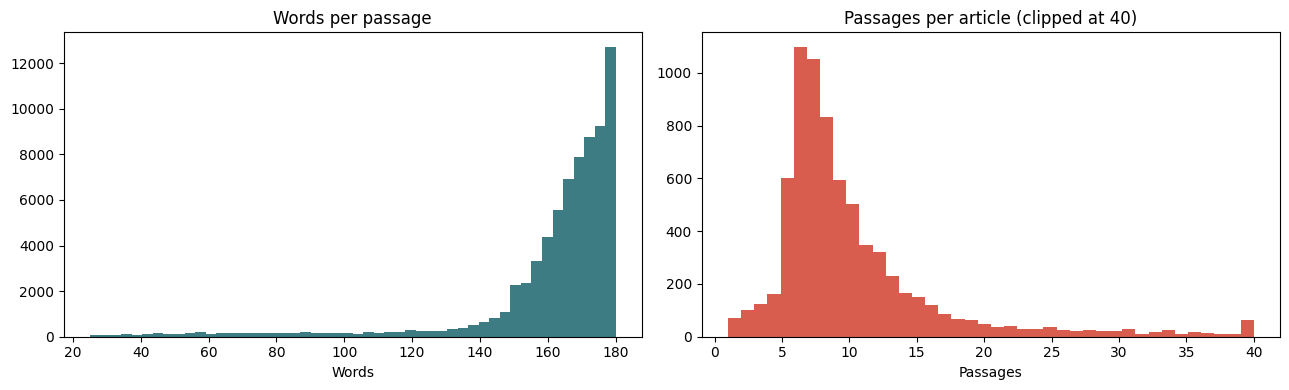

[20063_000] 2025-07-12 | Meta's Joel Kaplan: UK can lead in AI, if it avoids Brussels' failures
The UK is not alone in facing big economic challenges. Governments around the world are wrestling with vast
deficits, strains on public services, productivity crises and high prices. But crises can also be the jolt
that governments need to think and act big. The UK is better placed than most countries to establish itself as
a major AI power. It has a deep talent pool, world-leading universities and a long-standing culture of
innovation. But that won't count for much without strong political leadership. Sir Keir Starmer is certainly
talking the talk. He has called AI " the greatest force for change in the world right now " and laid out an
ambitious strategy to position the UK as an " AI maker, not an AI taker " by encouraging home-grown
innovation, investment in AI infrastructure and a transformation of the delivery of public services, such as
the NHS. 

[20063_001] 2025-07-12 | Meta's Joel K

In [17]:
passages_per_doc = passages.groupby("doc_id").size()

stats = pd.DataFrame({
    "articles": [passages["doc_id"].nunique()],
    "passages": [len(passages)],
    "median_passages_per_article": [passages_per_doc.median()],
    "median_words_per_passage": [passages["n_words"].median()],
    "max_words_per_passage": [passages["n_words"].max()],
})
display(stats)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.hist(passages["n_words"], bins=50, color="#3D7C83")
ax1.set_title("Words per passage")
ax1.set_xlabel("Words")
ax2.hist(passages_per_doc.clip(upper=40), bins=40, color="#D95D4F")
ax2.set_title("Passages per article (clipped at 40)")
ax2.set_xlabel("Passages")
plt.tight_layout()
plt.show()

# Example: the first three passages of one article
example_doc = passages["doc_id"].sample(1, random_state=RANDOM_STATE).iloc[0]
for _, row in passages[passages["doc_id"] == example_doc].head(3).iterrows():
    print(f"[{row['passage_id']}] {row['published_at']:%Y-%m-%d} | {row['title'][:70]}")
    print(textwrap.fill(row["text"], 110), "\n")

### Source check (Pascal)

The most frequent boilerplate passages come from a few sources: job postings on *builtin*, report templates on *skyquestt* and product text on *hiddenlayer*. In Stage 1 we already excluded *builtin*, *skyquestt* and *zbrain* from topic modeling, because they publish highly templated, non-journalistic content. These sources are still part of the RAG candidates, and removing the repeated passages does not change the character of these pages.

We therefore check the sources of the candidates: how many articles each domain contributes, how many of its passages were boilerplate, and how many of its texts are stored as a Python list (`['...`), which points to scraping artefacts.

In [18]:
STAGE1_EXCLUDED_DOMAINS = ["builtin", "skyquestt", "zbrain"]

candidates = df[df["gov_lexical"]]

domain_stats = candidates.groupby("domain").agg(
    articles=("title", "size"),
    list_format_share=("content", lambda s: s.astype(str).str.startswith("['").mean()),
)
domain_stats["passages"] = passages.groupby("domain").size()
domain_stats["passages_per_article"] = domain_stats["passages"] / domain_stats["articles"]
domain_stats = domain_stats.sort_values("articles", ascending=False)

print(f"Candidate articles: {len(candidates):,} from {len(domain_stats):,} domains\n")
print("Top 25 domains:")
display(domain_stats.head(25).round(2))

print("Domains excluded in Stage 1 (topic modeling):")
display(domain_stats.reindex(STAGE1_EXCLUDED_DOMAINS).round(2))

print("Domains with list-formatted content:")
display(domain_stats[domain_stats["list_format_share"] > 0.5].round(2))

# Random titles of the excluded and list-formatted sources
suspicious = STAGE1_EXCLUDED_DOMAINS + list(domain_stats[domain_stats["list_format_share"] > 0.5].index)
for domain in dict.fromkeys(suspicious):
    titles = candidates.loc[candidates["domain"] == domain, "title"]
    if len(titles) == 0:
        continue
    print(f"\n--- {domain} ({len(titles)} articles) ---")
    for title in titles.sample(n=min(5, len(titles)), random_state=RANDOM_STATE):
        print("  ", str(title)[:100])

Candidate articles: 7,264 from 288 domains

Top 25 domains:


,articles,list_format_share,passages,passages_per_article
domain,,,,
aijourn,476,1.00,3854,8.10
builtin,284,0.98,1911,6.73
kpmg,236,0.99,1768,7.49
theconversation,223,1.00,1603,7.19
skyquestt,189,0.97,2443,12.93
apnews,178,1.00,1754,9.85
zbrain,167,1.00,1312,7.86
ey,154,0.82,1571,10.20
aithority,151,1.00,1557,10.31


Domains excluded in Stage 1 (topic modeling):


,articles,list_format_share,passages,passages_per_article
domain,,,,
builtin,284,0.98,1911,6.73
skyquestt,189,0.97,2443,12.93
zbrain,167,1.00,1312,7.86


Domains with list-formatted content:


,articles,list_format_share,passages,passages_per_article
domain,,,,
aijourn,476,1.00,3854,8.10
builtin,284,0.98,1911,6.73
kpmg,236,0.99,1768,7.49
theconversation,223,1.00,1603,7.19
skyquestt,189,0.97,2443,12.93
...,...,...,...,...
smmt.co,1,1.00,8,8.00
spglobal,1,1.00,15,15.00
speedinvest,1,1.00,11,11.00



--- builtin (284 articles) ---
   How to Overcome Algorithmic Confirmation Bias
   Engineering Manager, Switchboard - GitLab
   4 New Year’ s Resolutions The AI Industry Needs in 2026
   Senior Backend Engineer, SSCS: Pipeline Security - GitLab
   What Is xAI? The Company Behind Grok

--- skyquestt (189 articles) ---
   ESD Face Shield Market Size, Share
   Middle School Market Size, Share
   Enterprise Data Management Market Growth Drivers, Trends, and Opportunities
   Cloud Managed Service Market Size, Share, and Regional Growth Insights 2026-2033
   Endpoint Security Market Size, Share, and Regional Outlook 2026-2033

--- zbrain (167 articles) ---
   GDPR Compliance Monitoring Agent
   RFQ Broadcast AI Agent
   RFQ Creation Agent
   Procurement Contract Compliance Agent
   Treasury Compliance Monitoring Agent

--- aijourn (476 articles) ---
   How Human Security Teams and AI Agents Work Together in Modern Security Operations
   How AI is Advancing Network Management System Developm

### Source check (Pascal)

The most frequent boilerplate passages come from a few sources: job postings on *builtin*, report templates on *skyquestt* and product text on *hiddenlayer*. In Stage 1 we already excluded *builtin*, *skyquestt* and *zbrain* from topic modeling, because they publish highly templated, non-journalistic content. These sources are still part of the RAG candidates, and removing the repeated sentences does not change the character of these pages.

We therefore check the sources of the candidates: how many articles each domain contributes, how many passages per article remain, and how many of its texts are stored as a Python list (`['...`), which points to scraping artefacts.

In [20]:
STAGE1_EXCLUDED_DOMAINS = ["builtin", "skyquestt", "zbrain"]

candidates = df[df["gov_lexical"]]

domain_stats = candidates.groupby("domain").agg(
    articles=("title", "size"),
    list_format_share=("content", lambda s: s.astype(str).str.startswith("['").mean()),
)
domain_stats["passages"] = passages.groupby("domain").size()
domain_stats["passages_per_article"] = domain_stats["passages"] / domain_stats["articles"]
domain_stats = domain_stats.sort_values("articles", ascending=False)

print(f"Candidate articles: {len(candidates):,} from {len(domain_stats):,} domains\n")
print("Top 25 domains:")
display(domain_stats.head(25).round(2))

print("Domains excluded in Stage 1 (topic modeling):")
display(domain_stats.reindex(STAGE1_EXCLUDED_DOMAINS).round(2))

print("Domains with list-formatted content:")
display(domain_stats[domain_stats["list_format_share"] > 0.5].round(2))

# Random titles of the excluded and list-formatted sources
suspicious = STAGE1_EXCLUDED_DOMAINS + list(domain_stats[domain_stats["list_format_share"] > 0.5].index)
for domain in dict.fromkeys(suspicious):
    titles = candidates.loc[candidates["domain"] == domain, "title"]
    if len(titles) == 0:
        continue
    print(f"\n--- {domain} ({len(titles)} articles) ---")
    for title in titles.sample(n=min(5, len(titles)), random_state=RANDOM_STATE):
        print("  ", str(title)[:100])

Candidate articles: 7,264 from 288 domains

Top 25 domains:


,articles,list_format_share,passages,passages_per_article
domain,,,,
aijourn,476,1.00,3854,8.10
builtin,284,0.98,1911,6.73
kpmg,236,0.99,1768,7.49
theconversation,223,1.00,1603,7.19
skyquestt,189,0.97,2443,12.93
apnews,178,1.00,1754,9.85
zbrain,167,1.00,1312,7.86
ey,154,0.82,1571,10.20
aithority,151,1.00,1557,10.31


Domains excluded in Stage 1 (topic modeling):


,articles,list_format_share,passages,passages_per_article
domain,,,,
builtin,284,0.98,1911,6.73
skyquestt,189,0.97,2443,12.93
zbrain,167,1.00,1312,7.86


Domains with list-formatted content:


,articles,list_format_share,passages,passages_per_article
domain,,,,
aijourn,476,1.00,3854,8.10
builtin,284,0.98,1911,6.73
kpmg,236,0.99,1768,7.49
theconversation,223,1.00,1603,7.19
skyquestt,189,0.97,2443,12.93
...,...,...,...,...
smmt.co,1,1.00,8,8.00
spglobal,1,1.00,15,15.00
speedinvest,1,1.00,11,11.00



--- builtin (284 articles) ---
   How to Overcome Algorithmic Confirmation Bias
   Engineering Manager, Switchboard - GitLab
   4 New Year’ s Resolutions The AI Industry Needs in 2026
   Senior Backend Engineer, SSCS: Pipeline Security - GitLab
   What Is xAI? The Company Behind Grok

--- skyquestt (189 articles) ---
   ESD Face Shield Market Size, Share
   Middle School Market Size, Share
   Enterprise Data Management Market Growth Drivers, Trends, and Opportunities
   Cloud Managed Service Market Size, Share, and Regional Growth Insights 2026-2033
   Endpoint Security Market Size, Share, and Regional Outlook 2026-2033

--- zbrain (167 articles) ---
   GDPR Compliance Monitoring Agent
   RFQ Broadcast AI Agent
   RFQ Creation Agent
   Procurement Contract Compliance Agent
   Treasury Compliance Monitoring Agent

--- aijourn (476 articles) ---
   How Human Security Teams and AI Agents Work Together in Modern Security Operations
   How AI is Advancing Network Management System Developm

In [19]:
remaining = passages[passages["text"].str.contains(r"""['"], ['"]""", regex=True)]
print(remaining["domain"].value_counts().head(5), "\n")
for _, row in remaining.sample(n=2, random_state=RANDOM_STATE).iterrows():
    match = re.search(r"""['"], ['"]""", row["text"])
    print(f"[{row['passage_id']}] ...{row['text'][max(0, match.start() - 120):match.end() + 120]}...\n")

domain
skyquestt         73
algorithmwatch    12
hbr                5
metro.co           5
dev                5
Name: count, dtype: int64 

[6076_002] ... craft a effective strategy, organisations must focus on a need for an " obsessive focus on results and sharp execution ", " value first " principles and " future cases " to enhance scalability and imagine new possibilities. Becky Power, Managi...

[16838_001] ...obtain, monitor or store all or any part of the content or Site, including whether manually or by way of any ' bot/robot', ' spider', ' scraper' or other automated software, device, algorithm, code, methodology, tool, process or similar technol...



### Source exclusions (Pascal)

The source check showed three groups of domains:

1. **Sources that are structurally not news articles:** job postings (*builtin*, e.g. "Senior Backend Engineer – GitLab"), market report templates (*skyquestt*), product pages of AI agents (*zbrain*) and model cards (*huggingface*, e.g. "microsoft/phi-4"). These pages describe no event and have no meaningful publication date, so they are not suitable evidence for a time-aware RAG system. We exclude these four domains completely. Three of them were already excluded from topic modeling in Stage 1.
2. **Mixed sources** such as consultancies (KPMG, EY, PwC) or vendor blogs publish both relevant and irrelevant articles. We do not exclude them by domain. The evaluated article-level filter of section 1.2 decides for each article.
3. **Specialised sources** that are valuable for our track, e.g. *hiddenlayer* (AI security research), *partnershiponai*, *algorithmwatch* or *ai-regulation*, are kept.

We also found that almost all articles in the dataset are stored as a Python list of paragraphs, not only a few sources. The conversion to continuous text in section 1.3 therefore affects the whole corpus.

In [21]:
EXCLUDED_DOMAINS = {
    "builtin":     "job postings and company profiles (also excluded in Stage 1)",
    "skyquestt":   "market report templates (also excluded in Stage 1)",
    "zbrain":      "product pages of AI agents (also excluded in Stage 1)",
    "huggingface": "model cards and dataset pages",
}

df["excluded_source"] = df["domain"].isin(EXCLUDED_DOMAINS)

excluded_overview = pd.DataFrame({
    "reason": EXCLUDED_DOMAINS,
    "candidate_articles": df[df["gov_lexical"]].groupby("domain").size().reindex(list(EXCLUDED_DOMAINS)),
    "passages": passages.groupby("domain").size().reindex(list(EXCLUDED_DOMAINS)),
}).fillna(0)
display(excluded_overview)

n_cand = df["gov_lexical"].sum()
n_cand_kept = (df["gov_lexical"] & ~df["excluded_source"]).sum()
n_pass_kept = (~passages["domain"].isin(EXCLUDED_DOMAINS)).sum()
print(f"Candidate articles: {n_cand:,} -> {n_cand_kept:,} after source exclusion")
print(f"Passages:           {len(passages):,} -> {n_pass_kept:,} after source exclusion")

# The passage file stays complete; the exclusion is applied together with
# the final topic filter of section 1.2 when we select the final corpus.

,reason,candidate_articles,passages
builtin,job postings and company profiles (also exclud...,284,1911
skyquestt,market report templates (also excluded in Stag...,189,2443
zbrain,product pages of AI agents (also excluded in S...,167,1312
huggingface,model cards and dataset pages,57,433


Candidate articles: 7,264 -> 6,567 after source exclusion
Passages:           72,576 -> 66,477 after source exclusion


## 1.4 Reproducible relation extraction with a controlled predicate schema (Pascal)

In Stage 1, LangExtract with `gemma3:4b` produced 998 relations with **421 distinct predicates**. Only 17 of 30 checked relations matched their source offsets, and after schema filtering only 29 relations remained. The Stage 1 feedback asked us to make the extraction **reproducible with a smaller, controlled predicate schema**. We changed four things:

1. **Smaller schema focused on governance.** The Stage 1 schema contained 8 entity types and general technology relations (e.g. `DEVELOPS`, `PARTNERS_WITH`). The new schema has **5 entity types and 9 predicates**. Every predicate describes a governance action and has a fixed **type signature** (allowed subject and object types).
2. **Schema enforced during generation.** Instead of LangExtract we call Gemini directly with **structured output**: the model must return JSON that follows our schema, and the predicate is an *enum*. The model therefore cannot invent new predicates.
3. **Passages as the extraction unit.** We extract from the passages of section 1.3, the same unit the RAG system retrieves. Every relation contains its `passage_id` and a **verbatim evidence quote**, which we check against the passage text.
4. **Reproducibility and API limits.** We use temperature 0 and send 10 passages per request. Every response is cached on Google Drive. A second run uses only the cache and gives exactly the same result, and an interrupted run continues where it stopped. With about 600 passages we need about 60 requests, which fits the free tier of the Gemini API. In Stage 1 the token limit was reached immediately, because LangExtract sent one request per text chunk.

### Schema definition (Pascal)

**Entity types**

| Type | Description | Examples |
|---|---|---|
| `LEGAL_INSTRUMENT` | Law, bill, regulation, executive order, code of practice, standard or official framework | EU AI Act, SB 53, GPAI Code of Practice, NIST AI RMF |
| `PUBLIC_AUTHORITY` | Government, legislature, regulator, agency, court or international organisation | European Commission, FTC, US Congress, Ofcom, UN |
| `ORGANIZATION` | Company, AI lab, NGO, publisher or industry association | OpenAI, Meta, The New York Times |
| `AI_SYSTEM` | Named AI model or AI product | ChatGPT, Grok, Claude, Llama |
| `PERSON` | Named individual | Gavin Newsom, Henna Virkkunen |

**Predicates**

| Predicate | Subject → Object | Meaning |
|---|---|---|
| `PROPOSES` | PUBLIC_AUTHORITY, PERSON → LEGAL_INSTRUMENT | drafts, introduces or proposes |
| `ADOPTS` | PUBLIC_AUTHORITY, PERSON → LEGAL_INSTRUMENT | passes, enacts, signs into law, formally publishes |
| `ENFORCES` | PUBLIC_AUTHORITY → LEGAL_INSTRUMENT | is responsible for or applies the enforcement of |
| `APPLIES_TO` | LEGAL_INSTRUMENT → ORGANIZATION, AI_SYSTEM | imposes obligations on, covers |
| `INVESTIGATES_OR_SANCTIONS` | PUBLIC_AUTHORITY → ORGANIZATION, AI_SYSTEM | investigates, fines, bans or orders |
| `SUES` | ORGANIZATION, PERSON, PUBLIC_AUTHORITY → ORGANIZATION | files a lawsuit against |
| `COMPLIES_WITH` | ORGANIZATION → LEGAL_INSTRUMENT | signs, commits to or complies with |
| `SUPPORTS` | ORGANIZATION, PERSON, PUBLIC_AUTHORITY → LEGAL_INSTRUMENT | publicly endorses or lobbies for |
| `OPPOSES` | ORGANIZATION, PERSON, PUBLIC_AUTHORITY → LEGAL_INSTRUMENT | criticises, refuses, challenges or lobbies against |

Every relation also has a **modality**: `actual` (it happened) or `planned` (announced or intended). For questions such as "When did the EU adopt the AI Act?", it matters whether something was done or only announced.

In [22]:
L, A, O, S, P = "LEGAL_INSTRUMENT", "PUBLIC_AUTHORITY", "ORGANIZATION", "AI_SYSTEM", "PERSON"

KG_SCHEMA = {
    "version": "stage3_v1",
    "entity_types": {
        L: "Law, bill, regulation, executive order, code of practice, standard or official framework",
        A: "Government, legislature, regulator, agency, court or international organisation",
        O: "Company, AI lab, NGO, publisher or industry association",
        S: "Named AI model or AI product",
        P: "Named individual",
    },
    "predicates": {
        "PROPOSES":                  {"subject": [A, P],    "object": [L],    "meaning": "drafts, introduces or proposes"},
        "ADOPTS":                    {"subject": [A, P],    "object": [L],    "meaning": "passes, enacts, signs into law, formally publishes"},
        "ENFORCES":                  {"subject": [A],       "object": [L],    "meaning": "is responsible for or applies the enforcement of"},
        "APPLIES_TO":                {"subject": [L],       "object": [O, S], "meaning": "imposes obligations on, covers"},
        "INVESTIGATES_OR_SANCTIONS": {"subject": [A],       "object": [O, S], "meaning": "investigates, fines, bans or orders"},
        "SUES":                      {"subject": [O, P, A], "object": [O],    "meaning": "files a lawsuit against"},
        "COMPLIES_WITH":             {"subject": [O],       "object": [L],    "meaning": "signs, commits to or complies with"},
        "SUPPORTS":                  {"subject": [O, P, A], "object": [L],    "meaning": "publicly endorses or lobbies for"},
        "OPPOSES":                   {"subject": [O, P, A], "object": [L],    "meaning": "criticises, refuses, challenges or lobbies against"},
    },
    "modalities": ["actual", "planned"],
}

ENTITY_TYPES = list(KG_SCHEMA["entity_types"])
PREDICATES = list(KG_SCHEMA["predicates"])

# Save the schema as part of our data dictionary
SCHEMA_FILE = os.path.join(STAGE3_FOLDER, "kg_schema_stage3.json")
with open(SCHEMA_FILE, "w", encoding="utf-8") as f:
    json.dump(KG_SCHEMA, f, indent=2)

print(f"{len(ENTITY_TYPES)} entity types, {len(PREDICATES)} predicates -> saved to {SCHEMA_FILE}")
pd.DataFrame([
    {"predicate": p, "subject": " | ".join(v["subject"]), "object": " | ".join(v["object"]), "meaning": v["meaning"]}
    for p, v in KG_SCHEMA["predicates"].items()
])

5 entity types, 9 predicates -> saved to /content/drive/MyDrive/CTA-media-analysis/stage3/kg_schema_stage3.json


,predicate,subject,object,meaning
0,PROPOSES,PUBLIC_AUTHORITY | PERSON,LEGAL_INSTRUMENT,"drafts, introduces or proposes"
1,ADOPTS,PUBLIC_AUTHORITY | PERSON,LEGAL_INSTRUMENT,"passes, enacts, signs into law, formally publi..."
2,ENFORCES,PUBLIC_AUTHORITY,LEGAL_INSTRUMENT,is responsible for or applies the enforcement of
3,APPLIES_TO,LEGAL_INSTRUMENT,ORGANIZATION | AI_SYSTEM,"imposes obligations on, covers"
4,INVESTIGATES_OR_SANCTIONS,PUBLIC_AUTHORITY,ORGANIZATION | AI_SYSTEM,"investigates, fines, bans or orders"
5,SUES,ORGANIZATION | PERSON | PUBLIC_AUTHORITY,ORGANIZATION,files a lawsuit against
6,COMPLIES_WITH,ORGANIZATION,LEGAL_INSTRUMENT,"signs, commits to or complies with"
7,SUPPORTS,ORGANIZATION | PERSON | PUBLIC_AUTHORITY,LEGAL_INSTRUMENT,publicly endorses or lobbies for
8,OPPOSES,ORGANIZATION | PERSON | PUBLIC_AUTHORITY,LEGAL_INSTRUMENT,"criticises, refuses, challenges or lobbies aga..."


### Selection of passages for extraction (Pascal)

Most passages contain no governance relation at all, e.g. introductions or background explanations. Sending them to the LLM would only cost requests. We therefore pre-select passages with three simple rules:

1. The article is in the **provisional governance corpus** (lexical candidate, positive semantic margin, not an excluded source). Relations of articles that the final filter of section 1.2 removes are dropped later.
2. The passage mentions at least one **legal instrument** (e.g. "... Act", "Executive Order", "Code of Practice", "SB 53") **and** at least one **public authority or organisation** (e.g. "Commission", "FTC", "Congress", "court", or a known AI company).
3. The passage contains a **trigger verb** for one of our predicates (e.g. *passed, signed, proposed, fined, sued, comply, oppose*).

From the eligible passages we draw **25 per month** (600 for 24 months) with a fixed random seed. This way the extraction covers the whole observation period and is not dominated by the peak months. Stage 1 used the same principle with 25 articles per month.

In [25]:
PASSAGES_PER_MONTH = 25

# 1. Legal instruments: generic patterns (case-sensitive, the text keeps its upper case)
LEGAL_PATTERN = re.compile(
    r"\b(?:[A-Z][\w.'-]*\s){0,5}(?:Act|Bill|Directive|Regulation|Executive Order|Code of Practice|"
    r"Framework|Convention|Treaty|Action Plan)\b"
    r"|\b(?:SB|AB|HB|S\.|H\.R\.)\s?\d{1,5}\b"
    r"|\b(?:GDPR|DSA|DMA|AI Act|NIST AI RMF|ISO/IEC 42001|ISO 42001)\b"
)

# 2. Public authorities and organisations
ACTOR_PATTERN = re.compile(
    r"\b(?:Commission|Parliament|Council|Congress|Senate|House|White House|Administration|Government|"
    r"Ministry|Department|Agency|Authority|Regulator|Court|Judge|Attorney General|Governor|President|"
    r"FTC|SEC|FCC|DOJ|NIST|CAISI|Ofcom|CNIL|Garante|ICO|AI Office|AI (?:Safety|Security) Institute|"
    r"United Nations|OECD|UNESCO|G7|"
    r"OpenAI|Anthropic|Google|DeepMind|Meta|Microsoft|Apple|Amazon|Nvidia|xAI|Mistral|DeepSeek|"
    r"TikTok|ByteDance|IBM|Perplexity|Stability AI|Midjourney|Character\.AI)\b"
)

# 3. Trigger verbs for our predicates
TRIGGER_PATTERN = re.compile(
    r"\b(?:propos\w*|introduc\w*|draft\w*|pass(?:ed|es)?|adopt\w*|enact\w*|sign(?:ed|s|ing)?|approv\w*|"
    r"publish\w*|enforc\w*|appl(?:y|ies|ied)|fin(?:ed|es)|investigat\w*|prob(?:e|ed|es|ing)|ban(?:s|ned)?|"
    r"order(?:ed|s)?|su(?:e|ed|es|ing)|lawsuit|compl(?:y|ies|ied|iance)|commit\w*|endors\w*|back(?:ed|s)?|"
    r"support\w*|oppos\w*|criticiz\w*|criticis\w*|challeng\w*|lobb\w*|veto\w*|block\w*)\b",
    re.IGNORECASE,
)

# Provisional governance corpus (final corpus is chosen in section 1.2)
provisional_docs = df.index[df["gov_v2"] & ~df["excluded_source"]]
pool = passages[passages["doc_id"].isin(provisional_docs)].copy()

pool["n_legal"] = pool["text"].str.count(LEGAL_PATTERN)
pool["n_actor"] = pool["text"].str.count(ACTOR_PATTERN)
pool["has_trigger"] = pool["text"].str.contains(TRIGGER_PATTERN)
pool["eligible"] = (pool["n_legal"] >= 1) & (pool["n_actor"] >= 1) & pool["has_trigger"]
pool["month"] = pool["published_at"].dt.to_period("M").astype(str)

eligible = pool[pool["eligible"]]
print(f"Passages of the provisional corpus: {len(pool):,}")
print(f"Eligible for extraction:            {len(eligible):,} ({len(eligible) / len(pool):.1%})")

# 25 passages per month, reproducible: shuffle once, then take the first 25 per month
extraction_set = (
    eligible.sample(frac=1, random_state=RANDOM_STATE)
    .groupby("month")
    .head(PASSAGES_PER_MONTH)
    .sort_values("passage_id")
    .reset_index(drop=True)
)
print(f"Selected for extraction:            {len(extraction_set):,} passages "
      f"from {extraction_set['doc_id'].nunique():,} articles\n")

display(extraction_set.groupby("month").size().rename("passages").to_frame().T)

# Two examples
for _, row in extraction_set.sample(n=2, random_state=RANDOM_STATE).iterrows():
    print(f"\n[{row['passage_id']}] {row['published_at']:%Y-%m-%d} | {row['title'][:80]}")
    print(textwrap.fill(row["text"], 110))

Passages of the provisional corpus: 37,786
Eligible for extraction:            1,670 (4.4%)
Selected for extraction:            598 passages from 417 articles



month,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,...,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
passages,23,25,25,25,25,25,25,25,25,25,...,25,25,25,25,25,25,25,25,25,25



[1815_000] 2024-10-14 | Breaking Down the Arguments for and against U.S. Antitrust Legislation
In many areas of the world, including the European Union, United Kingdom, South Korea, and Australia,
governments are considering new legislation to check the market power of a few dominant technology platforms.
Yet some of the most sweeping proposals are taking place within the U.S. Congress. In October 2020, the
majority staff of the House Subcommittee on Antitrust, Commercial, and Administrative Law published a set of
recommendations to promote competition in technology markets, the result of a 16-month investigation that
directed attention to the actions of Alphabet ( the parent company of Google), Amazon, Apple, and Facebook (
now Meta). The House Judiciary Committee advanced six bills in June 2021 that paralleled many of these
recommendations, focusing on the anticompetitive impacts of self-preferencing, mergers and acquisitions, data
accumulation, and network effects related to digita

### Extraction with Gemini and structured output (Pascal)

We send the selected passages in **batches of 10** to Gemini. The prompt contains:

- the entity types and predicates with their type signatures (from `KG_SCHEMA`);
- rules: only explicit relations, specific named entities, matching types, a verbatim evidence quote and the modality;
- **one invented example** (a fictional country and company). We do not use passages from our corpus as examples, so that the examples do not leak into the results.

The answer format is fixed by a **JSON schema** (`response_schema`), in which entity types, predicates and modalities are enums. Every raw response is saved in a cache file on Google Drive. The cache key is computed from the model, the prompt version and the passage texts, so a changed prompt automatically leads to new requests. If the rate limit is reached, the cell stops and can simply be run again later.

We first run **one batch as a test**, inspect the result, and only then run all batches.

We use the fixed model version `gemini-3.5-flash`. We do not use an alias such as `gemini-flash-latest`, because Google can replace the model behind an alias at any time, and a later run would then use a different model.

In [33]:
!pip install -q google-genai

from enum import Enum
from typing import List
from pydantic import BaseModel
from google import genai
from google.genai import types, errors
from google.colab import userdata

client = genai.Client(
    api_key=userdata.get("GEMINI_API_KEY"),
    http_options=types.HttpOptions(timeout=120_000),   # 120 seconds per request
)
EXTRACTION_MODEL = "gemini-3.5-flash"   # check the free-tier models in Google AI Studio if this fails
PROMPT_VERSION = "v1"
BATCH_SIZE = 10

# Response schema: enums make it impossible to return predicates or types outside our schema
EntityType = Enum("EntityType", {t: t for t in ENTITY_TYPES}, type=str)
Predicate = Enum("Predicate", {p: p for p in PREDICATES}, type=str)
Modality = Enum("Modality", {m: m for m in KG_SCHEMA["modalities"]}, type=str)


class Relation(BaseModel):
    passage_id: str
    subject: str
    subject_type: EntityType
    predicate: Predicate
    object: str
    object_type: EntityType
    modality: Modality
    evidence: str


class ExtractionResult(BaseModel):
    relations: List[Relation]


GENERATION_CONFIG = types.GenerateContentConfig(
    temperature=0,
    seed=RANDOM_STATE,
    response_mime_type="application/json",
    response_schema=ExtractionResult,
)

# Prompt
entity_type_lines = "\n".join(f"- {t}: {d}" for t, d in KG_SCHEMA["entity_types"].items())
predicate_lines = "\n".join(
    f"- {p}: {' | '.join(v['subject'])} -> {' | '.join(v['object'])} ({v['meaning']})"
    for p, v in KG_SCHEMA["predicates"].items()
)

EXAMPLE_PASSAGE = (
    "[EX_1] (published 2025-03-04) The Freedonian Parliament passed the Robot Liability Act on Monday. "
    "Acme AI said it would challenge the law in court. The Freedonian Data Authority also fined "
    "Acme AI 2 million euros over its chatbot Acmebot."
)
EXAMPLE_OUTPUT = json.dumps({"relations": [
    {"passage_id": "EX_1", "subject": "Freedonian Parliament", "subject_type": "PUBLIC_AUTHORITY",
     "predicate": "ADOPTS", "object": "Robot Liability Act", "object_type": "LEGAL_INSTRUMENT",
     "modality": "actual", "evidence": "The Freedonian Parliament passed the Robot Liability Act on Monday."},
    {"passage_id": "EX_1", "subject": "Acme AI", "subject_type": "ORGANIZATION",
     "predicate": "OPPOSES", "object": "Robot Liability Act", "object_type": "LEGAL_INSTRUMENT",
     "modality": "planned", "evidence": "Acme AI said it would challenge the law in court."},
    {"passage_id": "EX_1", "subject": "Freedonian Data Authority", "subject_type": "PUBLIC_AUTHORITY",
     "predicate": "INVESTIGATES_OR_SANCTIONS", "object": "Acme AI", "object_type": "ORGANIZATION",
     "modality": "actual", "evidence": "The Freedonian Data Authority also fined Acme AI 2 million euros"},
]}, indent=1)

PROMPT_TEMPLATE = f"""You extract AI-governance relations from news passages.

Entity types:
{entity_type_lines}

Predicates (allowed subject types -> allowed object types):
{predicate_lines}

Rules:
1. Extract only relations that are explicitly stated in the passage. Do not use background knowledge.
2. subject and object must be specific named entities, written as in the passage. If the passage says
   "the law" or "the company", use the name it refers to in the same passage. Skip generic groups
   without a name, such as "lawmakers", "tech companies" or "regulators".
3. The types of subject and object must be allowed for the predicate. If no predicate fits exactly,
   extract nothing.
4. evidence: copy the shortest sentence or clause from the passage that states the relation, word for word.
5. modality: "actual" if it happened, "planned" if it is announced, intended or expected.
6. passage_id: the id of the passage the relation comes from.
7. Many passages contain no relation. Then return nothing for them.

Example:
{EXAMPLE_PASSAGE}
Output:
{EXAMPLE_OUTPUT}

Passages:
{{passages}}
"""


def build_prompt(batch):
    passage_lines = "\n\n".join(
        f"[{row.passage_id}] (published {row.published_at:%Y-%m-%d}) {row.text}"
        for row in batch.itertuples()
    )
    return PROMPT_TEMPLATE.replace("{passages}", passage_lines)


def batch_key(batch):
    content = json.dumps([EXTRACTION_MODEL, PROMPT_VERSION, list(batch["passage_id"]), list(batch["text"])])
    return hashlib.md5(content.encode()).hexdigest()


batches = [extraction_set.iloc[i:i + BATCH_SIZE] for i in range(0, len(extraction_set), BATCH_SIZE)]
print(f"{len(extraction_set)} passages -> {len(batches)} batches of up to {BATCH_SIZE}")
print(f"Prompt length of the first batch: ~{len(build_prompt(batches[0]).split()):,} words")

598 passages -> 60 batches of up to 10
Prompt length of the first batch: ~2,119 words


In [ ]:
EXTRACTION_CACHE_FILE = os.path.join(STAGE3_FOLDER, "extraction_cache_gemini.jsonl")
MAX_BATCHES = None                 # test mode: 1 batch. Set to None for all batches.
SECONDS_BETWEEN_REQUESTS = 8    # stays below the requests-per-minute limit of the free tier
MAX_RETRIES = 4


def load_extraction_cache():
    cache = {}
    if os.path.exists(EXTRACTION_CACHE_FILE):
        with open(EXTRACTION_CACHE_FILE, encoding="utf-8") as f:
            for line in f:
                record = json.loads(line)
                cache[record["batch_key"]] = record
    return cache


def call_gemini(prompt):
    for attempt in range(MAX_RETRIES):
        try:
            response = client.models.generate_content(
                model=EXTRACTION_MODEL, contents=prompt, config=GENERATION_CONFIG
            )
            return response.text or '{"relations": []}'
        except errors.APIError as e:
            if e.code == 429 or e.code >= 500:
                wait = 30 * 2 ** attempt
                print(f"  API error {e.code}, waiting {wait}s (attempt {attempt + 1}/{MAX_RETRIES})")
                time.sleep(wait)
            else:
                raise
    return None   # still failing: probably the daily limit


extraction_cache = load_extraction_cache()
todo = [b for b in batches if batch_key(b) not in extraction_cache]
if MAX_BATCHES is not None:
    todo = todo[:MAX_BATCHES]
print(f"Cached batches: {len(batches) - len([b for b in batches if batch_key(b) not in extraction_cache])} "
      f"| to process now: {len(todo)}")

for batch in tqdm(todo, desc="extraction"):
    raw = call_gemini(build_prompt(batch))
    if raw is None:
        print("Stopped: rate limit still reached. Run this cell again later; finished batches are cached.")
        break
    record = {
        "batch_key": batch_key(batch), "model": EXTRACTION_MODEL, "prompt_version": PROMPT_VERSION,
        "passage_ids": list(batch["passage_id"]), "response": raw,
    }
    with open(EXTRACTION_CACHE_FILE, "a", encoding="utf-8") as f:
        f.write(json.dumps(record) + "\n")
    extraction_cache[record["batch_key"]] = record
    time.sleep(SECONDS_BETWEEN_REQUESTS)

# Flatten all cached responses of the current batches into one table
rows = []
for batch in batches:
    record = extraction_cache.get(batch_key(batch))
    if record is None:
        continue
    for rel in json.loads(record["response"]).get("relations", []):
        rows.append(rel)

relations_raw = pd.DataFrame(rows)
print(f"\nBatches done: {sum(batch_key(b) in extraction_cache for b in batches)} / {len(batches)}")
print(f"Raw relations: {len(relations_raw)}")
if len(relations_raw):
    display(relations_raw)

Cached batches: 1 | to process now: 59


extraction:   0%|          | 0/59 [00:00<?, ?it/s]

  API error 503, waiting 30s (attempt 1/4)
  API error 503, waiting 60s (attempt 2/4)
  API error 503, waiting 120s (attempt 3/4)


### Automatic checks of the extracted relations (Pascal)

The JSON schema guarantees valid predicates and entity types, but not that a relation is supported by its passage. We therefore check every relation automatically:

1. **Known passage:** the `passage_id` must belong to the passages sent in the request.
2. **Evidence found:** the evidence quote must appear in the passage, word for word. We compare lowercase texts without punctuation and allow small differences (fuzzy match ≥ 90).
3. **Arguments grounded:** subject and object must appear in the passage (fuzzy match ≥ 90). This catches entities that the model adds from background knowledge.
4. **Valid type signature:** the subject and object types must be allowed for the predicate (e.g. `SUES` needs an `ORGANIZATION` as object).

Only relations that pass all four checks are kept for the knowledge graph. In section 1.5 we then validate the important relations against their passages.

In [35]:
!pip install -q rapidfuzz
from rapidfuzz import fuzz

FUZZY_THRESHOLD = 90
passage_text = passages.set_index("passage_id")["text"]


def normalize_for_match(text):
    return re.sub(r"\W+", " ", str(text).lower()).strip()


def check_relations(relations, sent_passage_ids):
    checked = relations.copy()
    texts = checked["passage_id"].map(passage_text).fillna("")
    norm_texts = texts.map(normalize_for_match)

    checked["known_passage"] = checked["passage_id"].isin(sent_passage_ids)
    checked["evidence_found"] = [
        fuzz.partial_ratio(normalize_for_match(e), t) >= FUZZY_THRESHOLD
        for e, t in zip(checked["evidence"], norm_texts)
    ]
    checked["subject_found"] = [
        fuzz.partial_ratio(normalize_for_match(s), t) >= FUZZY_THRESHOLD
        for s, t in zip(checked["subject"], norm_texts)
    ]
    checked["object_found"] = [
        fuzz.partial_ratio(normalize_for_match(o), t) >= FUZZY_THRESHOLD
        for o, t in zip(checked["object"], norm_texts)
    ]
    checked["signature_valid"] = [
        st in KG_SCHEMA["predicates"][p]["subject"] and ot in KG_SCHEMA["predicates"][p]["object"]
        for p, st, ot in zip(checked["predicate"], checked["subject_type"], checked["object_type"])
    ]
    check_columns = ["known_passage", "evidence_found", "subject_found", "object_found", "signature_valid"]
    checked["passed_checks"] = checked[check_columns].all(axis=1)
    return checked


relations_checked = check_relations(relations_raw, set(extraction_set["passage_id"]))
display(relations_checked[["passage_id", "subject", "predicate", "object",
                           "known_passage", "evidence_found", "subject_found",
                           "object_found", "signature_valid", "passed_checks"]])

print("\nRelations passing each check:")
display(relations_checked[["known_passage", "evidence_found", "subject_found",
                           "object_found", "signature_valid", "passed_checks"]].sum().to_frame("relations"))
print("Predicates of the relations that passed all checks:")
display(relations_checked.loc[relations_checked["passed_checks"], "predicate"].value_counts().to_frame())

,passage_id,subject,predicate,object,known_passage,evidence_found,subject_found,object_found,signature_valid,passed_checks
0,10080_005,Department of Commerce,PROPOSES,Framework for AI Diffusion,True,True,True,True,True,True
1,10129_000,Chris Yiu,OPPOSES,AI Act,True,True,True,True,True,True
2,10129_000,Chris Yiu,OPPOSES,GDPR,True,True,True,True,True,True
3,1018_000,Gavin Newsom,OPPOSES,Senate Bill 1047,True,True,True,True,True,True
4,10454_011,U.S.,INVESTIGATES_OR_SANCTIONS,TikTok,True,True,True,True,True,True


[10080_005]  Department of Commerce (PUBLIC_AUTHORITY)  --PROPOSES [actual]-->  Framework for AI Diffusion (LEGAL_INSTRUMENT)
EVIDENCE: It can start by building on the Department of Commerce's Framework for AI Diffusion.
PASSAGE:
We should promote the diffusion of American AI to reinforce U.S. technology leadership and preempt China's
efforts to establish a Digital Silk Road for AI. At the same time, American AI companies' short-term demand
for energy and capital could, absent government involvement, lead to powerful AI infrastructure being built
abroad, which could potentially result in the most advanced models being developed beyond U.S. control and
more vulnerable to Chinese espionage. The Trump administration should not accept this. Instead, it should
develop a comprehensive strategy for spreading both U.S. AI hardware and software globally, while protecting
and reinforcing America's advantage. It can start by building on the Department of Commerce's Framework for AI
Diffusion. As 

**Test run (1 batch, 10 passages).** The model returned 5 relations, and all of them passed the automatic checks. A manual check against the passages found 4 correct relations (e.g. *Gavin Newsom OPPOSES Senate Bill 1047*, based on his veto) and one borderline case: *U.S. INVESTIGATES_OR_SANCTIONS TikTok* is based on a vague recollection of a panel speaker. We kept the prompt unchanged and ran all batches. Borderline cases are handled in the validation of section 1.5.